# AIR Homework 2 (Task 2)

## Setup

This notebook covers Task 2. Run the cells below before you start. They set up the notebook, load our working environment from `scene.py`, and import your code.

**NOTE:** This task uses your code in `task1.py`, so complete Task 1 before you start this task.

In [ ]:
%load_ext autoreload
%autoreload 2

# Set the EGL backend for MuJoCo on Linux (no effect on other operating systems)
import platform

if platform.system() == "Linux":
  %env MUJOCO_GL=egl

In [ ]:
# load our working environment from scene.py (see start_here.ipynb). load_scene replaces the
# model and the data, so we always read them through the module, e.g. scene.data.time
import scene
from scene import load_scene, render, set_seed, show_video

import time

import mediapy as media
import numpy as np

np.set_printoptions(precision=3, suppress=True)  # print numbers with 3 decimals

In [ ]:
# import your code. this notebook calls your code from Task 1 through t1 (e.g.
# t1.execute_with_monitoring), and your code for this task through t2 (e.g. t2.plan_with_simulation)
import task1 as t1
import task2 as t2

In [ ]:
import unittest

test = unittest.TestCase()  # used by the sanity checks

## Task 2: Integrated Task and Motion Planning

In Task 1 we put all our tools together in the simplest possible arrangement. The task planner plans, *then* the robot executes the plan one action at a time, with a skill for each action and a motion plan inside each skill. We closed the loop with a state estimator, so that the robot notices when the world does not match the plan and plans again. That system built a tower with an adversary rearranging its blocks. It also kept trying to stack a block where the arm cannot reach, and it parked blocks behind the wall when the tables next to the robot were just as good.

The problem with this arrangement is the word *then*. Information flows in one direction only, from the task planner to the motion layer, and so the task planner never learns what the motion layer knows, such as what is reachable, where there is room, and how much a motion costs. In this task we let information flow the other way too, which is what makes it task **and** motion planning. We will:

* watch the decoupled system fail on a table that has no room, a failure caused by geometry that the task planner cannot see,
* teach the task planner a **geometric fact**, `hasroom`, which the motion layer computes for it, and see the plan change,
* look at how far such a fact is from the truth, and at what replanning does and does not make up for,
* **measure what actions cost** with the motion planner, and hand the costs to the task planner so that it stops treating all tables alike,
* **simulate** a whole plan at the motion level before moving, to choose between alternatives, and to find out that an action is infeasible without moving the robot,
* **learn** from what the simulation finds infeasible, and tell the task planner, which proposes plans until one survives,
* and discuss what is left unsolved.

The decoupled task and motion planning system of Task 1 is in `task1.py`, and this notebook calls it through `t1`. Here is what it contains, for reference:

| what | functions |
|---|---|
| the task planner's model and the planner | `NTBW_DOMAIN`, `make_problem(facts, goal, domain, numbers)`, `solve(problem)`, `expected_states(problem, task_plan)` |
| the state estimator (the true state, read from the simulator's contacts) | `estimate_state()`, `true_state()`, `print_state(facts)` |
| skills | `pick_up(block)`, `stack(block, on_block)`, `put_down(block, table, xy)`, and the inverse kinematics behind them: `pick_configurations(block)`, `place_configurations(target_top)` |
| the sampler for `put-down` | `sample_on_table(table)`, `is_free(xy, exclude)`, `is_reachable(table, xy)`, `sample_free_spot(table, block)` |
| execution | `execute_action(action)`, `execute_with_monitoring(goal, domain, numbers, planner, estimator)` |
| odds and ends | `move_block(block, position)`, `draw_map(spots, colors, title)`, `table_surface(table)`, `table_point(table, xy)` |

Facts are tuples, as before: `("on", "b2", "b1")`, `("handempty",)`. In this task we will write new domains, planners and state estimators, and hand them to `execute_with_monitoring` (`domain`, `numbers`, `planner` and `estimator`). We will also need other arrangements of blocks: `load_scene(layout)` builds the world with any set of blocks, given as a dictionary from block names to colors and positions, and `load_scene()` without arguments gives the familiar scene.

In [ ]:
load_scene()
media.show_image(render())

### Task *and* motion planning

So far we expected the motion layer to simply work. We found one task plan and let the skills take it from there; when a skill failed or the world surprised us, we planned again. But replanning is just several rounds of task planning *then* motion planning. In each round the task planner knows as little about the physical world as it did in the round before, and so, as we saw at the end of Task 1, it can produce the same hopeless plan forever.

To call our system task *and* motion planning, the arrow has to point both ways. Until now we worked on making the motion layer understand the task planner (skills, samplers). Now we must make the task planner understand the motion layer.

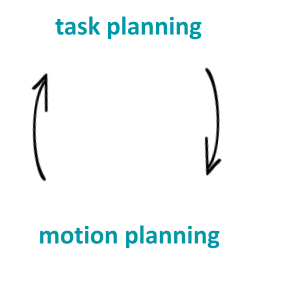

❓ **Which scenarios can you think of in which the task planner and the motion planner must work together to get the job done? List as many as you can before reading on.**

Here are some, in the order of the three symptoms we listed at the end of Task 1:

* **Infeasible actions.** An action is applicable in the abstract state but impossible in the world, for example because the table has no room for another block, the target is beyond the arm's reach, another object is in the way of every path. The task planner has to choose *other actions*, such as moving something out of the way first, and it will only do so if it is told why.
* **Blind choices.** The task planner chooses between options that look identical to it and are very different for the robot: which of two tables to put a block on, which of two red blocks to fetch, where on a table to put a block down so that it does not get in the way of what comes next.
* **Wasted effort.** A plan that cannot be executed, or that is needlessly expensive, is discovered one failed skill at a time, while the robot moves, when it could have been discovered by a much faster computation.

We will take them one at a time, using the N-Table Blocks World as before.

### The task planner does not see geometry

The task planner considers nothing outside its PDDL model, and the model does not capture the world. Take the tables. In PDDL, a table is a name: `put-down(b, t)` is applicable whenever the robot holds `b`. But a real table has a size, and that can matter in several ways:

1. What if there is no room left on the table for another block? Our PDDL model assumes that each table can take as many blocks as we like.
2. What if the only free place on the table is too far for the robot to reach? The task planner knows nothing about the robot's workspace.
3. What if there *is* enough room on the table in total, but the blocks are arranged so that no single free spot is large enough?

The figure below shows the third case. Blocks B2 to B10 are on table T2 and we need to move B1 from T3 to T2, but there is no spot on T2 where B1 would not collide with another block. A possible solution is to move B5 up a little, and make room.

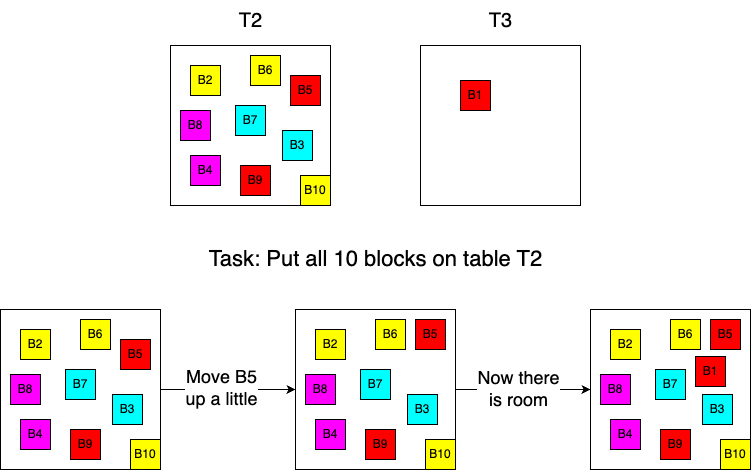

❓ **How could we overcome scenarios (1) and (2)? Note that your solution does not have to involve communication between the task planner and the motion planner.**

Some options: use bigger tables, or forbid goals that crowd a table (change the problem); write the number of blocks that fit on each table into the PDDL model by hand, and count (a richer model, which someone has to keep true); let the sampler look harder, or pack blocks tightly (a better motion layer). The option we will follow is to let the motion layer *tell* the task planner whether there is room, and let the task planner work out what to do about it.

#### A table with no room

Let's build the scenario: `b1` alone on table `t3`, and nine blocks on `t2`.

`full_table_layout` is provided in `task2.py`.

In [ ]:
FULL_LAYOUT = t2.full_table_layout()
load_scene(FULL_LAYOUT)
media.show_image(render())

Is `t2` full? There is a good deal of table left between the blocks, and a strip at the far edge. To find out, we use the sampler of Task 1. A spot is good for a block if it is *free* (not within a block width, plus a margin, of another block) and *reachable* (within the arm's comfortable reach, with collision-free configurations for placing). The map shows a few hundred random spots on `t2`; the dotted circle is the reach limit.

In [ ]:
np.random.seed(0)
spots = [t1.sample_on_table("t2") for _ in range(400)]
colors = ["green" if t1.is_free(xy) and t1.is_reachable("t2", xy) else "orange" if t1.is_free(xy) else "red" for xy in spots]
t1.draw_map(spots, colors, "spots on t2: occupied (red), free but out of reach (orange), free and reachable (green)")
print("a spot on t2 for b1:", t1.sample_free_spot("t2", "b1"))

There is not a single green spot. The gaps between the blocks are too narrow, and the free strip is out of reach. This is scenarios (2) and (3) at once. Now let's ask for `b1` on `t2`, with the system of Task 1.

In [ ]:
GOAL = "(and (ontable b1 t2))"

set_seed(42)
success, frames = t1.execute_with_monitoring(GOAL, max_replans=2)
print("success:", success)

The task planner sees nothing wrong: `pick-up(b1, t3)`, `put-down(b1, t2)`. The skill for `put-down` asks the sampler for a spot, the sampler finds none and the skill fails. The robot is left holding `b1`, the planner is asked again, and from the abstract state `(holding b1)` it proposes `put-down(b1, t2)`, again and again. Replanning cannot fix this failure, because nothing in the abstract state changes, and so the plan does not change either.

A person would immediately see a way out: take a block off `t2`, or shift one a little, to make room. The task planner is able to find both of these sequences of actions, but it has no reason to look for them.

#### Teaching the planner a geometric fact

We give it the reason, as a new predicate: `(hasroom ?t - table)`, which says that a block can be put down on table `?t`.

We met this predicate in the TAMP tutorial. A block can only be put down on a table if `hasroom` holds for that table, and `hasroom` holds for a table right after a block has been picked up from it. Here is our domain with `hasroom`:

`DOMAIN_WITH_HASROOM` is provided in `task2.py`.

In [ ]:
print(t2.DOMAIN_WITH_HASROOM)

❓ **Is adding the predicate to the domain enough? What else needs to be done?**

The domain says how `hasroom` is *used* and how actions *change* it. It does not say which tables have room right now, since that is part of the state, and the state comes from the state estimator. In Task 1 every fact of the abstract state was computed from the positions of the blocks. `hasroom` is a fact of a new kind. It is not about where things are but about what the robot *can do*, and the component that knows this is the sampler of the `put-down` skill. There is room on a table if and only if the sampler can find a spot on it.

#### `hasroom` in the state estimator

`hasroom(table)` returns whether there is room on the table for one more block, which is whether `sample_free_spot(table, block)` finds a spot (it returns a spot, or `None` after a thousand failed attempts; `block` is a block to ignore, the block that the robot is holding, if any, since it is not on any table).

`hasroom` is provided in `task2.py`.

In [ ]:
load_scene(FULL_LAYOUT)
print({table: t2.hasroom(table) for table in scene.TABLES})

The new estimator is the old one plus the new facts. We hand it to the executor with the `estimator` argument of `execute_with_monitoring`.

`estimate_state` (with `hasroom`) is provided in `task2.py`.

In [ ]:
t1.print_state(t2.estimate_state())

Note which component computes this fact. The sampler tests free space against the geometry of the blocks, and reachability with inverse kinematics and the collision checker. In other words, the motion layer gives information to the task planner, in the task planner's language. This is the arrow that was missing from the figure above.

Note also that the answer is not always correct. A sampler that returns a spot proves that there is room, but a sampler that returns nothing does not prove that there is none, since a thousand random spots can all miss a gap that is there. So `hasroom` can be wrong in one direction, and the more samples we take, the less often it is wrong. This is true for any geometric fact computed by sampling.

#### Planning with `hasroom`

Here is the plan from the estimated state, with the new domain. ❓ **Read it before you run the next cell. Will it work?**

In [ ]:
problem = t1.make_problem(t2.estimate_state(), GOAL, t2.DOMAIN_WITH_HASROOM)
print(", ".join(map(str, t1.solve(problem))))

In [ ]:
load_scene(FULL_LAYOUT)
set_seed(3)
success, frames = t1.execute_with_monitoring(GOAL, t2.DOMAIN_WITH_HASROOM, estimator=t2.estimate_state)
print("success:", success)
show_video(frames)
t1.draw_map(title="b1 on t2")

The task planner now knows that `t2` has no room, and that picking a block up from a table makes room on it. So it first picks up a block from `t2`, and only then brings `b1`. We passed information about the physical world from the motion layer (more precisely, from the sampler) to the task planner, and a problem that the decoupled system could not solve is solved.

But look at what the planner does with the block it picked up: it puts it down *on `t2`*. In its model, picking up from a table makes room and nothing says that putting down uses room up, so "pick up `b10` and put it back" is the cheapest way to make `hasroom` true. The planner found a loophole in our model, as planners often do. In the world, the sampler puts `b10` at a random spot in the gap it came from. If the spot is a little to the side, what remains of the gap is big enough for `b1`. This is the solution from the figure above ("move B5 up a little"), found by accident. If it is not, the state estimator reports that `(hasroom t2)` does not hold as expected, and the loop plans again, producing the same plan with a new sample. Our robot fidgets with a block until there is room. (Change the seed to see it take fewer or more attempts.)

❓ **Assume that every skill works perfectly. How can this system still fail to solve a problem like this one? What does the model not capture? What could be done about it, and is it worth doing?**

A few of the gaps between `hasroom` and the truth:

* If shifting one block could not make room, because the table really is full, the robot would fidget forever, because the planner is deterministic and the abstract state after each failed attempt is the same, so it keeps using the loophole. We could close the loophole (say, by making `put-down` use up the room that a `pick-up` made), at the price of a more complicated model.
* The planner does not know when a table *becomes* full. Ask it to bring two blocks to a table that has room for one and it will plan to put both down; only after the first does the estimator report that the room is gone. The plan cannot succeed, and only replanning saves it.
* Whether there is "room" depends on the size of the object, on what else is nearby, and on how the arm approaches, so a single fact per table is a crude summary.

We could go on refining: count the free places on each table, divide the tables into cells, add a predicate for reachability. Each refinement makes the task planning problem bigger and slower, and none of them captures the geometry completely, because geometry is continuous and PDDL is not. Instead, our solution relies heavily on replanning. The model is optimistic, and the estimator corrects it as the robot goes. This is a legitimate choice: it is up to the designer to decide how much of the world to capture in the task model, and how much to leave to be discovered during execution. A classic paper on this tradeoff is *Hierarchical Task and Motion Planning in the Now* by Leslie Pack Kaelbling and Tomás Lozano-Pérez (ICRA 2011).

### Reasoning about the cost of moving

Feasibility is not the only thing the task planner does not know about. It also does not know the cost of actions. Recall the question from the TAMP tutorial: when the goal is given by *color*, which block should the robot use? And recall the tower of Task 1, where the planner parked a block behind the wall although the tables next to the robot were just as good.

Here is a scene for the first question. We want a red block on table `t3`.

In [ ]:
RED_LAYOUT = {
    "b1": ("red", [0.05, -0.6, 0.74]),
    "b2": ("red", [0.55, 0.0, 0.74]),
    "b3": ("yellow", [0.55, 0.0, 0.78]),
    "b4": ("green", [-0.1, 0.55, 0.74]),
    "b5": ("blue", [0.15, 0.7, 0.74]),
}

load_scene(RED_LAYOUT)
media.show_image(render())

There are two red blocks. `b2` is right in front of the robot, under a yellow block. `b1` is clear, behind the window. Which one should the robot bring?

Our PDDL model, in which every action costs 1, prefers `b1`, which takes only two actions (pick it up and put it down). Fetching `b2` takes four, because the yellow block has to be unstacked and put somewhere first. But is `b1` really the cheaper choice?

❓ **How could we change the PDDL model to account for the cost of the motions? How could we account for it without changing the PDDL model? Which is better?**

We could write costs into the model, since PDDL lets actions have costs (we will see how shortly), but where would the numbers come from? Unless the robot makes the same motion every time it executes an action, no fixed number is the true cost: the cost of `pick-up(b1, t1)` depends on where the arm is, what it holds and what is in the way. Besides, why should *we* work out the costs? We have a motion planner that plans the very motions the robot will make. Let's ask it.

#### Measuring a motion

We measure the effort of a motion by the length of its path in configuration space: the sum of the distances between consecutive waypoints, in radians. This is a simplification (it ignores speed, torque and time spent grasping), but it is easy to compute, and it grows with the things we care about.

Implement `path_length(waypoints)`, which returns the length of a path given as a list of configurations (arrays of six joint angles). The cell after the sanity check uses it to compare the motion from `HOME` to above the red block behind the window with the motion to above the green block on `t3`.

**TODO:** implement `path_length` in `task2.py`.

From here on, cells that start with `# sanity check` run a few quick checks on what you just implemented, and print what they found. If one fails, something is wrong. If it passes, you are heading in the right direction, but your code may still have bugs: these checks are not the tests we will run on your submission.

In [ ]:
# sanity check: path_length
q0, q1, q2 = np.zeros(6), np.array([0.3, 0.4, 0, 0, 0, 0]), np.array([0.3, 0.4, 1.2, 0, 0, 0])
test.assertAlmostEqual(t2.path_length([q0, q1]), 0.5)
test.assertAlmostEqual(t2.path_length([q0, q1, q2]), 0.5 + 1.2)

# the length is measured along the path, not from its start to its end
test.assertAlmostEqual(t2.path_length([q0, q1, q0]), 1.0)
test.assertAlmostEqual(t2.path_length([q0, q2, q1]), np.linalg.norm(q2) + 1.2)

# a path that stays where it is has no length
test.assertAlmostEqual(t2.path_length([q1]), 0.0)
test.assertAlmostEqual(t2.path_length([q1, q1, q1]), 0.0)

print(f"path_length sanity checks passed. length = {t2.path_length([q0, q1, q2]):.2f} rad")

In [ ]:
set_seed(1)
for block in ["b1", "b4"]:
    q_high, q_low = t1.pick_configurations(block)
    waypoints = scene.plan(scene.HOME, q_high, verbose=False)
    print(f"from HOME to above {block}: {len(waypoints)} waypoints, {t2.path_length(waypoints):.2f} rad")

Going through the window is several times longer than turning to the next table, because the arm has to fold itself through the frame.

#### Costs in the task planner's model

The simplest way to use this is to measure once and write the numbers into the model. The tables do not move, so we can ask the motion planner how far each table is from the robot's home configuration, as an average over a few random spots (and a few runs of the planner, which is itself random).

`access_cost` is provided in `task2.py`.

In [ ]:
set_seed(1)
ACCESS_COST = {table: float(t2.access_cost(table)) for table in scene.TABLES}
print({table: round(cost, 2) for table, cost in ACCESS_COST.items()})

Add action costs to `DOMAIN_WITH_COSTS`, which starts as a copy of the domain with `hasroom`. PDDL describes action costs with *numeric functions*, numbers that are part of the state, and a *metric* to minimize. Add the requirement `:action-costs`, and declare the numeric functions `(total-cost)`, `(access-cost ?t - table)` and `(stack-cost)` in a `:functions` section, right after the predicates:

```
(:functions (total-cost) - number
            (access-cost ?t - table) - number
            (stack-cost) - number)
```

An action adds to the total cost with an effect such as `(increase (total-cost) (stack-cost))`. `pick-up` and `put-down` should cost the access cost of their table, `(access-cost ?t)`. `stack` and `unstack` do not say where they happen, so charge them a flat `(stack-cost)`. The values of the functions, and the metric `(:metric minimize (total-cost))`, go into the problem, and `make_problem` writes them for you when you give it `numbers`.

**TODO:** add action costs to `DOMAIN_WITH_COSTS` in `task2.py`.

In [ ]:
# sanity check: DOMAIN_WITH_COSTS
from unified_planning.plans import ActionInstance, SequentialPlan
from unified_planning.shortcuts import PlanValidator, SequentialSimulator

load_scene()
check_numbers = {("access-cost", "t1"): 7, ("access-cost", "t2"): 2, ("access-cost", "t3"): 3, ("stack-cost",): 5}
check_facts = t1.estimate_state() | {("hasroom", table) for table in scene.TABLES}
try:
    check_problem = t1.make_problem(check_facts, "(and (on b3 b1))", t2.DOMAIN_WITH_COSTS, check_numbers)
except Exception as e:
    raise AssertionError(f"a problem with action costs does not parse with DOMAIN_WITH_COSTS. Did you declare the requirement and the numeric functions? ({e})") from e


def check_plan(*actions):
    return SequentialPlan([ActionInstance(check_problem.action(name), [check_problem.object(arg) for arg in args]) for name, *args in actions])


def check_cost(plan):
    with PlanValidator(problem_kind=check_problem.kind) as validator:
        result = validator.validate(check_problem, plan)
    test.assertTrue(result.metric_evaluations, "the problem has no metric to evaluate. Did you add the :action-costs requirement?")
    return list(result.metric_evaluations.values())[0]


# unstack and stack cost the stack cost, and put-down and pick-up the access cost of their table
test.assertEqual(check_cost(check_plan(("unstack", "b2", "b1"), ("put-down", "b2", "t3"), ("pick-up", "b3", "t2"), ("stack", "b3", "b1"))), 5 + 3 + 2 + 5)
test.assertEqual(check_cost(check_plan(("unstack", "b2", "b1"), ("put-down", "b2", "t1"), ("pick-up", "b3", "t2"), ("stack", "b3", "b1"))), 5 + 7 + 2 + 5)

# the planner finds the cheapest plan: it puts b2 down on t2, which is the cheapest table
check_task_plan = t1.solve(check_problem)
test.assertEqual(t2.plan_cost(check_task_plan, check_numbers), 5 + 2 + 2 + 5)

# hasroom still has its part: a block cannot be put down on a table without room
no_room_problem = t1.make_problem(t1.estimate_state() | {("hasroom", "t1")}, "(and (on b3 b1))", t2.DOMAIN_WITH_COSTS, check_numbers)
with SequentialSimulator(no_room_problem) as simulator:
    state = simulator.apply(simulator.get_initial_state(), no_room_problem.action("unstack"), [no_room_problem.object("b2"), no_room_problem.object("b1")])
    test.assertFalse(simulator.is_applicable(state, no_room_problem.action("put-down"), [no_room_problem.object("b2"), no_room_problem.object("t3")]),
                     "put-down should require hasroom")

print("DOMAIN_WITH_COSTS sanity checks passed. the cheapest plan:", ", ".join(map(str, check_task_plan)))

The numbers go into the problem. Fast Downward wants integer costs, so we count in tenths of a radian. For the flat rate of `stack` and `unstack` we take the median of the three tables, as a typical trip.

`plan_cost` is provided in `task2.py`.

In [ ]:
NUMBERS = {("access-cost", table): int(round(10 * cost)) for table, cost in ACCESS_COST.items()}
NUMBERS[("stack-cost",)] = int(np.median(list(NUMBERS.values())))
print(NUMBERS)

Back to the red blocks. We could state the goal by color and let the planner choose the block (we will see how later). Here, we do the choosing outside the planner: one goal per red block, a plan for each, and we compare.

In [ ]:
CANDIDATE_GOALS = {"b1": "(and (ontable b1 t3))", "b2": "(and (ontable b2 t3))"}

load_scene(RED_LAYOUT)
facts = t2.estimate_state()
candidate_plans = {}
for block, goal in CANDIDATE_GOALS.items():
    candidate_plans[block] = t1.solve(t1.make_problem(facts, goal, t2.DOMAIN_WITH_COSTS, NUMBERS))
    print(f"{block}: {len(candidate_plans[block])} actions, cost {t2.plan_cost(candidate_plans[block], NUMBERS)}: " + ", ".join(map(str, candidate_plans[block])))

If we count actions, `b1` wins, with two actions against four. If we count the costs measured by the motion planner, `b2` wins, because four short motions in front of the robot are cheaper than two trips through the window.

The same costs settle the question that Task 1 left open. Here is the tower of five blocks on `t2`, in the original scene, planned twice from the same state: once counting actions, once with our costs.

In [ ]:
TOWER_GOAL = "(and (ontable b1 t2) (on b2 b1) (on b3 b2) (on b4 b3) (on b5 b4))"

load_scene()
facts = t2.estimate_state()
for name, domain, numbers in [("counting actions", t2.DOMAIN_WITH_HASROOM, None), ("with motion costs", t2.DOMAIN_WITH_COSTS, NUMBERS)]:
    task_plan = t1.solve(t1.make_problem(facts, TOWER_GOAL, domain, numbers))
    print(f"{name}: {len(task_plan)} actions, cost {t2.plan_cost(task_plan, NUMBERS)}: " + ", ".join(map(str, task_plan)))

Both plans have twelve actions, and to a planner that counts actions they are equally good. They differ in one place: where to park `b2` while `b1` is moved. The cost-aware planner parks it on a table next to the robot and not behind the wall. Let's run both and see whether the robot agrees. The video shows the second run, at six times real time.

In [ ]:
robot_time = {}
for name, domain, numbers in [("counting actions", t2.DOMAIN_WITH_HASROOM, None), ("with motion costs", t2.DOMAIN_WITH_COSTS, NUMBERS)]:
    print(f"--- {name} ---")
    load_scene()
    set_seed(42)
    success, frames = t1.execute_with_monitoring(TOWER_GOAL, domain, numbers, estimator=t2.estimate_state)
    robot_time[name] = scene.data.time

for name, seconds in robot_time.items():
    print(f"{name}: {seconds:.0f} s of robot time")
show_video(frames[::2])  # six times real time

The task planner used the costs measured by the motion layer to choose a plan, and the robot finished sooner.

❓ **What is wrong with these costs?** They are *static*: computed once, for a typical case, from one starting configuration. The cost of reaching a table depends on where the arm is coming from: two actions in a row at the same table need hardly any travel, and our model charges the full trip twice. `stack` and `unstack` pay a flat rate wherever the stack stands (how would you change the domain so that they could be charged by table too?). And the numbers do not take into account the block being carried, or the blocks that happen to be in the way.

The tower shows how rough this is. Count the trips through the window in the two plans: there are four in each. What the first plan really pays for is two extra actions *behind* the wall, where even a short motion is slow and cramped; our model charged them as two full trips. So the costs led to the better plan, but not quite for the right reason.

#### Simulating a plan

The alternative is to leave the PDDL model alone and ask the motion layer about the plan itself: the actions of the plan, in the current world, starting from where the arm is now. We do not have to move the robot to find out. Every skill begins by computing its configurations and planning a path, and only then moves. If we do just the computing, and then *teleport* the arm and the block to where the motion would have taken them (our collision checker has been teleporting the robot all along), we can simulate a whole plan without moving the robot, and without even running the physics, and add up the lengths of the paths.

`simulate_action` does this for one action: it returns the length of the motions that the skill would make (the planned approach, plus the straight descent and lift), or `None` if the skill would fail, and leaves the simulator in the state the action would produce. `simulate_plan` does it for a plan, and puts the world back as it was.

`simulate_action` and `simulate_plan` are provided in `task2.py`.

Let's simulate the two ways of bringing a red block to `t3`. The motion planner is random, and so is the sampler, so we simulate each plan a few times and average.

❓ **Before you run the cell: which block do you think the robot should bring, and by how much is it cheaper?**

In [ ]:
load_scene(RED_LAYOUT)
simulated_cost = {}
for block, task_plan in candidate_plans.items():
    print(f"{block}: " + ", ".join(map(str, task_plan)))
    totals = []
    start = time.time()
    for seed in [42, 84, 126]:
        set_seed(seed)
        costs = t2.simulate_plan(task_plan)
        totals.append(sum(costs) if None not in costs else np.inf)
        print("   ", [None if cost is None else round(float(cost), 1) for cost in costs], f"total {totals[-1]:.1f} rad")
    simulated_cost[block] = np.mean(totals)
    print(f"    mean {simulated_cost[block]:.1f} rad ({time.time() - start:.0f} s of computation)")

The simulation agrees with the static costs on the winner, and it gives us more detail. Each action has its own cost, the short hops between neighboring spots are cheap, and the trip back out through the window with a block in the gripper is as long as the trip in.

So far we read the numbers ourselves. Now let's have the robot act on them. `execute_cheapest` takes several goals, any one of which would do. It plans for each from the current state, simulates each plan a few times, and hands the goal whose plan is cheapest in simulation to the closed loop of Task 1. Our task planner is deterministic, so the plan that the loop executes is the plan that the robot simulated (unless something goes wrong and the loop replans).

`execute_cheapest` is provided in `task2.py`.

In [ ]:
load_scene(RED_LAYOUT)
set_seed(42)
success, frames = t2.execute_cheapest(CANDIDATE_GOALS.values(), t2.DOMAIN_WITH_COSTS, NUMBERS)
chosen_time = scene.data.time
print(f"success: {success}, {chosen_time:.0f} s of robot time")
show_video(frames)

Was the robot right? A simulation that teleports cannot tell us that, so we have to execute. Let's execute the plan that the robot rejected, the one that brings `b1`, from the same start, and compare.

In [ ]:
load_scene(RED_LAYOUT)
set_seed(42)
success, _ = t1.execute_with_monitoring(CANDIDATE_GOALS["b1"], t2.DOMAIN_WITH_COSTS, NUMBERS, estimator=t2.estimate_state)
print(f"the rejected plan: {scene.data.time:.0f} s of robot time, against {chosen_time:.0f} s for the chosen one")

❓ **What are the limitations of this way of estimating costs? Do you have better ideas?**

Some of them:

* **Path length is not cost.** Time, energy and risk are what we care about; a short path may be slow, and a path that passes close to an obstacle may fail. We could simulate the plan with the physics and the controller, and not with teleportation, and measure time, but that is even slower.
* **It is noisy.** The planner and the sampler are random: the path that the robot follows when it executes is not the path it simulated, and the spot where it puts a block down is not the spot it simulated either. A real system would *keep* what it simulated, the spots and the paths, and execute those.
* **It is expensive.** Each simulated plan costs seconds of motion planning. We compared two candidates. A task planner looks at thousands of states, and cannot call the motion planner for each. Deciding *when* to ask the motion layer (for every action considered? only for complete plans? only when something fails?) is the central design question of integrated task and motion planning.
* **It evaluates plans, it does not find them.** The candidates still came from a task planner with a crude cost model. The two approaches complement each other: static costs can guide the search, and simulation can check and compare what the search proposes.

#### Simulation also finds what cannot be done

A plan whose action returns `None` is a plan that will fail. Remember the last experiment of Task 1: `b4` sits at the far corner of `t3`, out of reach, and we ask for `b5` on top of it. The decoupled system picked `b5` up and then kept trying to stack it until it gave up.

In [ ]:
load_scene()
height, _, _ = t1.table_surface("t3")
t1.move_block("b4", [-0.25, 0.9, height + scene.BLOCK_HALF_HEIGHT])

task_plan = t1.solve(t1.make_problem(t2.estimate_state(), "(and (on b5 b4))", t2.DOMAIN_WITH_COSTS, NUMBERS))
start = time.time()
costs = t2.simulate_plan(task_plan)
for action, cost in zip(task_plan, costs):
    print(f"{action}: " + ("infeasible" if cost is None else f"{cost:.1f} rad"))
print(f"({time.time() - start:.1f} s of computation, {scene.data.time:.1f} s of robot time)")
t1.draw_map(title="b4 at the far corner: nothing can be stacked on it")

The robot now knows that the plan fails at `stack(b5, b4)` before it has moved at all. What should it do with this knowledge? As before, we turn it into something the task planner understands, and plan again.

#### Learning from simulation

A failed action teaches the robot a fact of the same kind as `hasroom`, which is about what the robot can do and not about where things are. We give the task planner two such facts:

* `(cannot-pick ?b)`: the robot cannot pick up (or unstack) block `?b` where it is,
* `(cannot-stack-on ?b)`: nothing can be stacked on block `?b` where it is.

Note the words *where it is*. Each fact is about a block at its current position, and once the block moves, it no longer applies. In the domain below, `pick-up` and `unstack` can only be applied to a block that is not known to be unpickable, `stack` only onto a block that is not known to be a bad base, and picking a block up forgets what was known about stacking on it. These are *negative preconditions*, such as `(not (cannot-pick ?b))`, which need the requirement `:negative-preconditions`. (We also declare `:existential-preconditions`, for a goal that we will meet shortly.) Like `hasroom`, the facts are optimistic: the planner assumes that every action can be done until the robot learns otherwise.

`DOMAIN_WITH_LESSONS` is provided in `task2.py`.

In [ ]:
print(t2.DOMAIN_WITH_LESSONS)

There is a difference from `hasroom`, though. The estimator computes `hasroom` for every table in every state. The new facts are learned *lazily*: only for the actions that the task planner actually proposes and that the simulation finds infeasible. Here we could afford to check every block in advance, but a robot in a richer world cannot check every action in every state, so most integrated planners let the task planner point at the actions that matter, to keep the work of the motion layer manageable.

Implement `lesson(action)`, which returns the fact (a tuple) that the robot learns when the simulation finds the action infeasible: `("cannot-pick", block)` for `pick-up` or `unstack` of `block`, and `("cannot-stack-on", block)` for `stack` of anything onto `block`. A failed `put-down` teaches nothing that these two facts can say (`hasroom` is there for that): return `None`. Recall from `simulate_action` (in `task2.py`) how to read the name and the arguments of an action.

**TODO:** implement `lesson` in `task2.py`.

In [ ]:
load_scene()
task_plan = t1.solve(t1.make_problem(t2.estimate_state(), "(and (on b2 b5))", t2.DOMAIN_WITH_COSTS, NUMBERS))
for action in task_plan:
    print(action, "->", t2.lesson(action))

In [ ]:
# sanity check: lesson
from unified_planning.plans import ActionInstance

load_scene()
check_problem = t1.make_problem(t1.estimate_state(), "(and (on b2 b5))")


def check_action(name, *args):
    return ActionInstance(check_problem.action(name), [check_problem.object(arg) for arg in args])


test.assertEqual(t2.lesson(check_action("pick-up", "b3", "t2")), ("cannot-pick", "b3"))
test.assertEqual(t2.lesson(check_action("unstack", "b2", "b1")), ("cannot-pick", "b2"))
test.assertEqual(t2.lesson(check_action("stack", "b2", "b5")), ("cannot-stack-on", "b5"))
test.assertIsNone(t2.lesson(check_action("put-down", "b2", "t3")))
print("lesson sanity checks passed.")

Now the robot needs a memory. `LESSONS` keeps every fact it learned, together with the position of the block at the time, and the estimator adds to the state the lessons about blocks that have not moved since. That way the planner's expectations (picking a block up forgets what was known about it) and the estimator agree, and the monitor of Task 1 sees no difference between them.

`plan_with_simulation` is the conversation between the task planner and the motion layer: the task planner proposes a plan, the robot simulates it, and if an action turns out to be infeasible, the robot learns a lesson, adds it to the problem and asks for another plan. It stops when a plan survives simulation, or when the task planner has nothing more to propose, or when there is nothing to learn. Like `solve`, it takes a problem and returns a plan or `None`, so we can hand it to the closed loop of Task 1 as its planner. From then on, the robot simulates every plan before it moves, also when it replans after a surprise.

There is one subtlety. The simulation can fail at a block that the plan itself has moved, say a `stack` onto a block that the plan has just put down somewhere. That failure is about a spot in the simulated world, and our facts can only talk about blocks where they are *now*. In that case we learn nothing and give up.

Implement `plan_with_simulation(problem, max_lessons)`. In each round, propose a plan with `solve` (and give up, returning `None`, if there is none), and simulate it with `simulate_plan`. If every action of the plan is feasible, return the plan. Otherwise, find the lesson of the first infeasible action with `lesson`, remember it in `LESSONS` together with the current position of its block, add the fact to the initial state of the problem with `add_fact`, and ask for a plan again, up to `max_lessons` times. The printouts are written for you.

**TODO:** implement `plan_with_simulation` in `task2.py`. `LESSONS`, `remembered_lessons`, `estimate_state_with_lessons` and `add_fact` are provided there.

Here is a scene to try it on. We want the red block `b5` on a green block, any green block. PDDL can state such a goal with `exists`: `(exists (?b - block) (and (bcolor ?b green) (on b5 ?b)))` holds if `b5` is on some block `?b` whose color is green. The task planner chooses the green block. There are two: `b4`, at the far corner of `t3` where we left it, and `b3`, on `t2`, at the bottom of a stack of three.

❓ **Before you run the cell: which plans will the task planner propose, and what will the robot learn from each?**

In [ ]:
height, _, _ = t1.table_surface("t3")
z = height + scene.BLOCK_HALF_HEIGHT  # the height of the center of a block on a table
LESSON_LAYOUT = {
    "b1": ("yellow", [0.6, 0.1, z + 2 * scene.BLOCK_HALF_HEIGHT]),
    "b2": ("blue", [0.6, 0.1, z + 4 * scene.BLOCK_HALF_HEIGHT]),
    "b3": ("green", [0.6, 0.1, z]),
    "b4": ("green", [-0.25, 0.9, z]),
    "b5": ("red", [0.15, 0.7, z]),
}
GREEN_GOAL = "(exists (?b - block) (and (bcolor ?b green) (on b5 ?b)))"

load_scene(LESSON_LAYOUT)
t2.LESSONS.clear()
set_seed(42)
start = time.time()
success, frames = t1.execute_with_monitoring(GREEN_GOAL, t2.DOMAIN_WITH_LESSONS, NUMBERS, planner=t2.plan_with_simulation,
                                             estimator=t2.estimate_state_with_lessons)
print(f"success: {success} ({time.time() - start:.0f} s of computation, {scene.data.time:.0f} s of robot time)")
t1.print_state(t2.estimate_state_with_lessons())
show_video(frames)

The first plan is the obvious one: pick up `b5` and stack it on `b4`. The simulation finds that nothing can be stacked on `b4`, and the robot learns it. The task planner's second plan is to move `b4` to a place where stacking on it is possible (picking `b4` up forgets the lesson about stacking on it). The simulation finds that `b4` cannot even be picked up, and the robot learns that too. Only then does the task planner choose the more expensive plan of clearing `b3`, with six actions, and this plan survives simulation. The robot did not move until it had a plan that survived. In Task 1, it picked `b5` up and then kept trying to stack it until it gave up.

Many integrated task and motion planners are built around this loop, in which the task planner proposes plans, the motion layer checks them, and the failures are returned to the task planner as new facts, until a plan survives.

❓ **What can go wrong with these lessons?**

Some things:

* **A lesson is a guess about the cause.** The simulation tells us that an action failed, but not why. `stack(b5, b4)` failed because of where `b4` is, and we blamed `b4`; but an action can also fail because of the block being carried or a block in the way, and then the lesson blames the wrong block. And the motion planner is random: a path that it did not find in one try may well exist, and then the lesson forbids a feasible action until the block moves.
* **The vocabulary is small.** We can say "not where it is now", but not "not on that spot" or "not higher than two blocks". When the simulation fails at a block that the plan itself has moved, we learn nothing and give up. Richer facts (about regions, heights, grasps) say more, and cost more to compute and to plan with.
* **The number of rounds can explode.** Each round costs a call to the task planner and a simulated plan. Here three rounds took seconds. With many blocks and many ways to fail, the task planner may propose many plans that fail for similar reasons, one at a time. Learning facts that rule out many plans at once is a large part of the research on integrated task and motion planning.

#### The full table, once more

Let's solve the problem of the full table once more (`FULL_LAYOUT`, `GOAL`), in closed loop, this time with the domain that has both `hasroom` and costs. ❓ **Before you run it: what do you expect the robot to do with the block it picks up from `t2`, and why?**

In [ ]:
load_scene(FULL_LAYOUT)
set_seed(3)
success, frames = t1.execute_with_monitoring(GOAL, t2.DOMAIN_WITH_COSTS, NUMBERS, estimator=t2.estimate_state)
print("success:", success)
show_video(frames)
t1.draw_map(title="b1 on t2, and one block moved away")

With the costs we measured, putting a block down on `t3` is a little cheaper than putting it down on `t2`, so the planner carries the block away and does not put it back: no fidgeting, and `b1` goes straight into the gap. Note that we did not fix the loophole in `hasroom`. It is still there; the costs only made it less attractive, by a small margin. (If your measured costs came out the other way round, the robot fidgets as before.) Two imperfect pieces of information from the motion layer turned out to be better than one, and integrated systems are often built this way in practice.

### What we did not get into

We captured only a small fraction of what makes integrating task and motion planning hard. Among the things we left out:

* **Partial observability.** We used the true state of the world. How should the robot plan when it is uncertain about the state, and when looking is itself an action that takes time?
* **Multiple agents.** How should several robots choose their actions so that they help, and do not collide with, one another?
* **Navigation.** What if the robot has to drive somewhere before it can act, and where it parks decides what it can reach?
* **Richer geometry.** Grasps from the side, objects that are not boxes, objects that block one another, tools.
* **Learning.** Where do the skills, the samplers, the predicates and the cost models come from, if nobody writes them by hand?

If you want to read on, the survey *Integrated Task and Motion Planning* by Garrett, Chitnis, Holladay, Kim, Silver, Kaelbling and Lozano-Pérez (Annual Review of Control, Robotics, and Autonomous Systems, 2021) is a good place to start.

## Conclusion

In this task we made the task planner listen to the motion layer. We gave it a geometric fact, `hasroom`, computed by the sampler, and it solved a problem that the decoupled system could only fail at; we also saw how loosely such a fact fits the world, and how much we lean on replanning to cover the difference. We measured the cost of motions with the motion planner and wrote the costs into the task planner's model, and the robot stopped parking blocks behind the wall. And we let the robot simulate its plans at the motion level before moving: to choose the cheapest of several plans, and to find out what cannot be done, learn it, and tell the task planner, which proposed plans until one survived.

Together, the two tasks covered two ways of putting a task planner and a motion planner together: one after the other, with the world checked after every action (Task 1), and in conversation (Task 2).